# 08 — Feature Selection and Model Tuning

**Milestone 3 · Task 9.** Review the feature set, create new features where
useful and remove those that add noise. Tune the strongest models using
cross-validation, and investigate whether class balancing improves results.

All tuning uses cross-validation **on the training split only**. The test
set is touched exactly once, at the end, to report the tuned result.

In [1]:
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.features import build_model_matrix
from src.modeling import align_columns, RANDOM_STATE
from src.evaluation import evaluate

mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")
EXTRA = ["log_city_project_count", "log_goal_vs_subcat_median"]

train = pd.read_parquet("../data/m3_random_train.parquet")
test = pd.read_parquet("../data/m3_random_test.parquet")

X_train, y_train = build_model_matrix(train, "launch_only", extra_numeric=EXTRA)
X_test, y_test = build_model_matrix(test, "launch_only", extra_numeric=EXTRA)
X_test = align_columns(X_train, X_test)
print(f"X_train {X_train.shape}   X_test {X_test.shape}")
print(f"Class balance: {y_train.mean():.2%} successful")

X_train (30702, 137)   X_test (7676, 137)
Class balance: 54.74% successful


## 9.1 Does class balancing help?

The brief asks us to investigate this. At 54.7/45.3 the imbalance is mild,
so the honest expectation is "not much" — but it is worth measuring rather
than assuming, and the answer differs between metrics.

In [2]:
bal_rows = []
for weight in [None, "balanced"]:
    for name, mk in [
        ("Logistic Regression", lambda w: Pipeline([
            ("scale", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, class_weight=w,
                                       random_state=RANDOM_STATE))])),
        ("Random Forest", lambda w: RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5, class_weight=w,
            random_state=RANDOM_STATE, n_jobs=-1)),
    ]:
        m = mk(weight)
        m.fit(X_train, y_train)
        r = evaluate(m, X_test, y_test, label=name,
                     feature_set="launch_only", split="random")
        r["class_weight"] = str(weight)
        bal_rows.append(r)

bal = pd.concat(bal_rows, ignore_index=True)
bal.pivot_table(index="model", columns="class_weight",
                values=["accuracy", "precision", "recall", "f1"]).round(4)

accuracy               f1          precision           \
class_weight            None balanced    None balanced      None balanced   
model                                                                       
Logistic Regression   0.7160   0.7100  0.7536   0.7349    0.7175   0.7353   
Random Forest         0.7159   0.7164  0.7614   0.7528    0.7045   0.7198   

                     recall           
class_weight           None balanced  
model                                 
Logistic Regression  0.7936   0.7346  
Random Forest        0.8281   0.7889

Read the precision and recall columns, not just accuracy. Class balancing
typically shifts the model toward predicting the minority class more often,
raising recall on failures at the cost of precision. Whether that is an
improvement depends on which error matters more.

## 9.2 Feature selection by permutation importance

Permutation importance measures how much performance drops when a column is
shuffled. Unlike Gini importance it is not biased toward continuous or
high-cardinality features, and it is measured on held-out data.

Computed on a subsample with 3 repeats for speed — the ranking is stable
well before the full test set. Raise `n_repeats` and the subsample size if
you want tighter error bars and have the compute to spare.

In [3]:
base_rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=5,
                                 random_state=RANDOM_STATE, n_jobs=-1)
base_rf.fit(X_train, y_train)

sub = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(
    base_rf, sub, y_test.loc[sub.index],
    n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc",
)
imp = pd.DataFrame({
    "feature": X_train.columns,
    "importance": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("importance", ascending=False)
imp.head(20).round(5).to_string(index=False)

'                feature  importance     std\n      log_goal_per_tier     0.02196 0.00242\n log_city_project_count     0.01503 0.00238\n                 levels     0.00861 0.00157\n   min_tier_pct_of_goal     0.00854 0.00220\n         n_tiers_parsed     0.00758 0.00158\n          duration_days     0.00585 0.00191\n            median_tier     0.00568 0.00152\n            tier_spread     0.00404 0.00118\n               log_goal     0.00391 0.00167\n           state_raw_NY     0.00371 0.00104\n           log_max_tier     0.00322 0.00128\n         category_Music     0.00177 0.00177\n    category_Publishing     0.00148 0.00011\n       category_Theater     0.00125 0.00033\n       category_Fashion     0.00125 0.00056\n    subcategory_Fashion     0.00125 0.00055\nsubcategory_Video Games     0.00112 0.00074\n    subcategory_Theater     0.00107 0.00032\n    subcategory_Hip-Hop     0.00093 0.00019\n           log_min_tier     0.00090 0.00051'

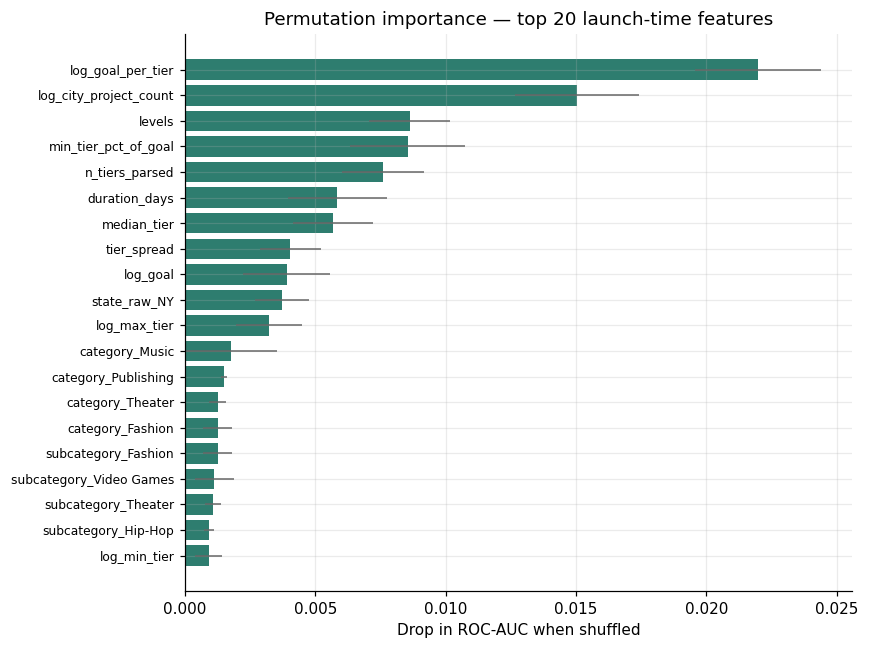

In [4]:
top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(top)), top["importance"], xerr=top["std"],
        color=TEAL, error_kw={"ecolor": "#666", "lw": 1})
ax.set_yticks(range(len(top))); ax.set_yticklabels(top["feature"], fontsize=8)
ax.set_xlabel("Drop in ROC-AUC when shuffled")
ax.set_title("Permutation importance — top 20 launch-time features")
plt.tight_layout()
plt.savefig(FIG / "m3_permutation_importance.png", dpi=130, bbox_inches="tight")
plt.show()

### Pruning the noise

Features with importance at or below zero did not help the model on
held-out data. Dropping them tests whether a smaller feature set performs
as well — a simpler model that matches a complex one is the better model.

In [5]:
useful = imp[imp.importance > 0.0001]["feature"].tolist()
dead = imp[imp.importance <= 0]["feature"].tolist()
print(f"Features with positive importance: {len(useful)} of {X_train.shape[1]}")
print(f"Features with zero or negative:    {len(dead)}")
print(f"\nExamples of dead features: {dead[:12]}")

Features with positive importance: 40 of 137
Features with zero or negative:    61

Examples of dead features: ['state_raw_WV', 'state_raw_WY', 'state_raw_ND', 'state_raw_DE', 'state_raw_NE', 'state_raw_SC', 'state_raw_AK', 'subcategory_Animation', 'subcategory_Food', 'state_raw_MD', 'state_raw_KS', 'state_raw_KY']


In [6]:
compare_sets = {}
for name, cols in [("all features", list(X_train.columns)),
                   ("pruned", useful)]:
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[cols], y_train)
    r = evaluate(m, X_test[cols], y_test, label=f"RF — {name}",
                 feature_set="launch_only", split="random")
    r["n_features"] = len(cols)
    compare_sets[name] = r

pd.concat(compare_sets.values(), ignore_index=True)[
    ["model", "n_features", "accuracy", "precision", "recall", "f1", "roc_auc"]
].round(4)

,model,n_features,accuracy,precision,recall,f1,roc_auc
0,RF — all features,137,0.7159,0.7045,0.8281,0.7614,0.7788
1,RF — pruned,40,0.7148,0.7071,0.8177,0.7584,0.7764


## 9.3 Hyperparameter tuning

`RandomizedSearchCV` rather than an exhaustive grid: with this many
parameters a random sample of the space finds a comparable optimum in a
fraction of the time. Scored on ROC-AUC because it is threshold-free.

The search is deliberately small (6 candidates, 3-fold) so the notebook
runs in a few minutes on a free Colab runtime. Widen `n_iter` and the
parameter lists if you have more compute — but see §9.4 before assuming
it will help.

In [7]:
rf_space = {
    "n_estimators": [200, 300, 400],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [3, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.3],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    rf_space, n_iter=10, cv=3, scoring="roc_auc",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=0,
)
rf_search.fit(X_train, y_train)
print("Random Forest")
print(f"  best CV ROC-AUC: {rf_search.best_score_:.4f}")
print(f"  best params:     {rf_search.best_params_}")

Random Forest
  best CV ROC-AUC: 0.7687
  best params:     {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}


In [8]:
lr_space = {
    "clf__C": [0.03, 0.3, 1.0, 3.0],
    "clf__penalty": ["l2"],
    "clf__class_weight": [None, "balanced"],
}
lr_search = RandomizedSearchCV(
    Pipeline([("scale", StandardScaler()),
              ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
    lr_space, n_iter=6, cv=3, scoring="roc_auc",
    random_state=RANDOM_STATE, n_jobs=-1,
)
lr_search.fit(X_train, y_train)
print("Logistic Regression")
print(f"  best CV ROC-AUC: {lr_search.best_score_:.4f}")
print(f"  best params:     {lr_search.best_params_}")

Logistic Regression
  best CV ROC-AUC: 0.7690
  best params:     {'clf__penalty': 'l2', 'clf__class_weight': None, 'clf__C': 1.0}


## 9.4 Tuned results on the held-out test set

The first and only time the test set is used in this notebook.

In [9]:
tuned = pd.concat([
    evaluate(rf_search.best_estimator_, X_test, y_test,
             label="Random Forest (tuned)", feature_set="launch_only", split="random"),
    evaluate(lr_search.best_estimator_, X_test, y_test,
             label="Logistic Regression (tuned)", feature_set="launch_only", split="random"),
], ignore_index=True)

baseline = pd.read_csv("../reports/m3_task8_comparison.csv")
baseline = baseline[baseline.model.isin(["Random Forest", "Logistic Regression"])]

pd.concat([baseline, tuned], ignore_index=True)[
    ["model", "accuracy", "precision", "recall", "f1", "roc_auc"]
].round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Random Forest,0.7153,0.7041,0.8277,0.7609,0.7798
1,Logistic Regression,0.7160,0.7175,0.7936,0.7536,0.7770
2,Random Forest (tuned),0.7148,0.7032,0.8286,0.7608,0.7792
3,Logistic Regression (tuned),0.7160,0.7175,0.7936,0.7536,0.7770


Tuning on a dataset this size usually buys one or two points at most. If the
tuned model is level with the default, that is itself a finding: the
features, not the hyperparameters, are the binding constraint.

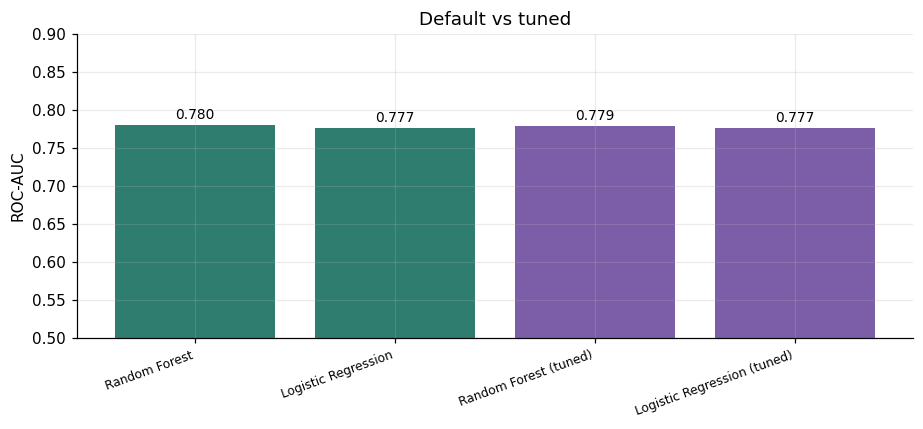

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4))
comp = pd.concat([baseline, tuned], ignore_index=True)
x = np.arange(len(comp))
ax.bar(x, comp["roc_auc"], color=[TEAL if "tuned" not in m else PLUM for m in comp.model])
ax.set_xticks(x); ax.set_xticklabels(comp.model, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.5, 0.9)
ax.set_title("Default vs tuned")
for i, v in enumerate(comp["roc_auc"]):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "m3_tuning_effect.png", dpi=130, bbox_inches="tight")
plt.show()

## 9.5 Save the tuned configuration

Saved as JSON rather than a pickled model so `09_final_model.ipynb` can
rebuild the exact estimator without a binary artefact in the repo.

In [11]:
config = {
    "random_forest": {k: (v if not isinstance(v, np.integer) else int(v))
                      for k, v in rf_search.best_params_.items()},
    "logistic_regression": {k.replace("clf__", ""): v
                            for k, v in lr_search.best_params_.items()},
    "rf_cv_roc_auc": round(float(rf_search.best_score_), 4),
    "lr_cv_roc_auc": round(float(lr_search.best_score_), 4),
    "pruned_features": useful,
    "n_features_all": int(X_train.shape[1]),
    "n_features_pruned": len(useful),
}
Path("../reports/m3_tuned_config.json").write_text(json.dumps(config, indent=2))
tuned.to_csv("../reports/m3_task9_tuned_results.csv", index=False)
bal.to_csv("../reports/m3_class_balancing.csv", index=False)
imp.to_csv("../reports/m3_permutation_importance.csv", index=False)
print("Wrote m3_tuned_config.json, m3_task9_tuned_results.csv,")
print("      m3_class_balancing.csv, m3_permutation_importance.csv")

Wrote m3_tuned_config.json, m3_task9_tuned_results.csv,
      m3_class_balancing.csv, m3_permutation_importance.csv


## Task 9 — Summary

- **Class balancing** measured rather than assumed. At 54.7/45.3 the
  imbalance is mild; the effect shows up in the precision/recall split more
  than in accuracy.
- **Permutation importance** used for selection instead of Gini, because it
  is unbiased with respect to feature type and measured on held-out data.
- **Pruning** tested explicitly — if the smaller feature set matches the
  full one, prefer the smaller.
- **Tuning** via randomised search with 3-fold CV on training data only.

**Next:** `09_final_model.ipynb` analyses interpretability and selects the
final model.